<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QCNN_MalwareMultiSection_Quertier2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-QCNN for Windows PE malware detection: Quertier and Barrue 2024 step by step

**Paper.** Tony Quertier and Gregoire Barrue (Orange Innovation, Rennes), *Towards an In-Depth Detection of Malware Using Multi-QCNN*, in L. Franco et al. (eds.), ICCS 2024, LNCS 14837, pp. 405-412, Springer. DOI [10.1007/978-3-031-63778-0_29](https://doi.org/10.1007/978-3-031-63778-0_29).

**What is the problem?** A Windows program (a *PE file*, an `.exe` or `.dll`) is built from a header and several *sections*: `.text` (the machine code), `.data` and `.rdata` (variables and constants), `.rsrc` (icons, menus, embedded resources, a favourite hiding place for payloads) and `.reloc` (relocation tables). The authors ask whether a **few-qubit** quantum model can detect malware if, instead of squeezing the whole file into one 8-qubit input, we give **every section its own small quantum model** and then combine their opinions.

**What this notebook does**
1. Downloads real EMBER 2018 raw PE records from a public Hugging Face mirror and cuts three disjoint, class-balanced sub-datasets from them (the paper's *D1* trains the QCNNs, *D2* trains the combining function, *D3* is the final test).
2. Turns every section of every file into an 8-number vector (the substitute for the paper's 8 x 8 grayscale section image, see the table below) and rescales it into angles in [0, pi/2].
3. Builds the **8-qubit QCNN of the paper** (3 convolution + 3 pooling layers, measurement of the last qubit) in Qiskit, draws it, and trains one copy per section with SPSA for 5 epochs.
4. Scores every file with the five QCNNs (score -1 when a section is missing), trains a **scoring function** (XGBoost, LightGBM, Random Forest, majority vote) on these five scores, and tests the whole pipeline on D3.
5. Trains the paper's reference model: **one QCNN on the whole file** (PCA to 8 inputs) and compares.
6. Trains classical models on exactly the same inputs, re-draws the paper's Tables 1, 2, 3a and 3b with our numbers beside the paper's, and prints a verdict per claim.

**How to run.** Open in Google Colab (CPU runtime is enough), then *Runtime -> Run all*. `FAST_MODE = True` finishes in a few minutes; `FAST_MODE = False` is the full run (3 seeds, about 1 200 files per class and sub-dataset) and takes roughly 15-25 minutes on a laptop CPU. The data come from a public Hugging Face repository; if you have a Hugging Face token, store it in Colab *Secrets* as `HF_TOKEN` (it is optional for this public repository, and the token is never written into the notebook).

**What you get at the end:** the five per-section QCNN accuracies (paper Table 1), the scoring-function comparison (Table 2), the final multi-QCNN versus single-QCNN comparison (Table 3), the same models in classical form, and a "reproduced / not reached / cannot be checked" verdict per claim.

## The paper in one page

* **Problem.** Detect Windows PE malware with quantum machine learning while using **at most 8 qubits** (so the model stays close to what real quantum hardware offers).
* **Data (paper).** Two datasets, BODMAS and *PEMachineLearning* (their ref. [13]); the raw PE files are needed because the files are cut into sections. Three disjoint sub-datasets of **20 000 benign + 20 000 malware** each: D1 trains the QCNNs on the binary's sections, D2 trains the final scoring function, D3 is the test set. D1 and D2 are split 70 / 30 into train / validation.
* **Preprocessing.** The file is parsed with LIEF to find the start and end of each section. Five sections are used (`.text`, `.data`, `.rdata`, `.rsrc`, `.reloc`) because they exist in most files. Each section is turned into an **8 x 8 grayscale image** (Nataraj et al. 2011 style), reduced with **PCA from 64 to 8 features**, and mapped into [0, pi/2].
* **Encoding (Eq. 1).** `|phi(x)> = tensor_i ( cos(x_i)|0> + sin(x_i)|1> )`, i.e. one RY(2 x_i) rotation per qubit.
* **QCNN (Fig. 3 and 4).** 8 qubits, 3 layers; each layer is a convolution (parameterised two-qubit gates entangling neighbours) followed by a pooling (parameterised two-qubit gates, then half of the qubits are dropped). The **last qubit** is measured in the Z basis. Optimiser: SPSB (a simultaneous-perturbation optimiser, Hoffmann and Brown 2022), **5 epochs**.
* **Missing sections.** If a file lacks a section its score is **-1** (a neutral 0.5 was tried first and rejected as biased).
* **Scoring function.** The five QCNN scores form a vector; XGBoost, LightGBM, Random Forest and a majority vote are compared; the final model uses XGBoost.
* **Reported numbers.** Table 1 (per section, train acc / test acc / test F1): text 0.67 / 0.69 / 0.68, data 0.56 / 0.55 / 0.70, rdata 0.66 / 0.66 / 0.78, rsrc 0.65 / 0.63 / 0.72, reloc 0.69 / 0.70 / 0.67. Table 2 (scoring function, train acc / F1, test acc / F1): XGBoost 0.89 / 0.90 / 0.84 / 0.85, LGBM 0.84 / 0.86 / 0.82 / 0.85, RF 0.99 / 0.99 / 0.85 / 0.86, majority vote test 0.4 / 0.27. Table 3a (whole pipeline on D3): RF 0.82 / 0.80, XGBoost 0.83 / 0.83. Table 3b (one QCNN on the whole-file image): train 0.68 / 0.70, test 0.60 / 0.66.
* **Claims.** (a) single sections are weak (0.55-0.70) but comparable to a QCNN on the whole file; (b) combining five section QCNNs with a learned scoring function lifts accuracy and F1 by about 20 points (0.83 versus 0.60); (c) XGBoost is slightly better than RF on the final test; (d) a majority vote is useless here; (e) the scores show which section looks suspicious.

### What follows the paper and what had to be chosen

The most important deviation first: **the paper cuts raw PE files into section images. No public dataset offers raw benign + malware PE bytes together** (BODMAS ships malware binaries on request only, and benign files are not redistributable; downloading malware binaries is also not something a classroom notebook should do). The notebook therefore uses the public **EMBER 2018 raw feature records** (one JSON record per PE file), which contain, for every section, its **name, size, virtual size, entropy and characteristic flags**. These *section descriptors* replace the grayscale pixels of the section. Everything downstream (PCA to 8 numbers, angle encoding, QCNN, scores, scoring function) follows the paper.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | BODMAS + PEMachineLearning, raw PE files | **EMBER 2018 raw feature JSONL** (Anderson and Roth 2018), Hugging Face repo `cycloevan/ember`, labelled files only (benign / malware) |
| Section input | 8 x 8 grayscale image of the section bytes (via LIEF) | 13 **section descriptors** per section: log size, log virtual size, entropy, virtual/raw size ratio, size / file size, and 8 characteristic flags (code, init. data, uninit. data, execute, read, write, discardable, shared). Byte content of a section is **not** available in EMBER |
| Reduction to 8 inputs | PCA 64 -> 8 | StandardScaler -> PCA 13 -> 8, fitted per section on that section's D1 training rows only |
| Whole-file input (Table 3b) | PCA of the 64 x 64 image of the whole file | PCA of EMBER's **256-value byte-entropy histogram** of the whole file (a 16 x 16 "image" of the file), 256 -> 8, fitted on D2-train |
| Sample size | 3 x (20 000 + 20 000) | 3 x (N_PER_CLASS + N_PER_CLASS) with N_PER_CLASS = 250 (FAST) / 1 200 (full), drawn from the first lines of the 6 EMBER training files |
| Split | D1 / D2 / D3, 70 / 30 train / validation for D1 and D2 | same; D1-train and D2-train fit models, D1-val / D2-val are the "test" columns of Tables 1 and 2, D3 is the final test |
| QCNN layout | 8 qubits, 3 conv + 3 pool layers, Z on the last qubit (Fig. 3) | the same; gate content of Fig. 4 is not in the extracted text, so the **Qiskit QCNN tutorial blocks** (3 parameters each, Cong et al. style) are used (`# CHOICE:`), one parameter set shared inside a layer, 18 trainable parameters in total |
| Loss | not stated | mean squared error between `<Z>` and the target (+1 malware, -1 benign) (`# CHOICE:`) |
| Optimiser | SPSB, 5 epochs | standard **SPSA** (the closest relative; SPSB's constant-scaling gradient estimate is not in Qiskit), 5 epochs, batch 16; learning rate chosen from {0.3, 1.0} on an inner validation part of the training data (`# CHOICE:`) |
| Score of a section | probability of malware | `(1 + <Z>) / 2`; -1 if the section is absent |
| Scoring functions | XGBoost, LGBM, RF, majority vote | the same libraries; hyper-parameters (200 trees, depth 4 for boosting) are `# CHOICE:`; majority vote = malware when at least 3 of the 5 sections say `score > 0.5` (absent sections vote benign) (`# CHOICE:`) |
| Simulator | not stated | exact state-vector simulation. For speed the gate list of the Qiskit circuit is replayed by a small NumPy simulator that is **asserted equal** to Qiskit (`Statevector`, `EstimatorQNN`) in the circuit section |
| Seeds | not stated | 1 seed (FAST) / 3 seeds (full); each seed redraws the three sub-datasets and re-initialises the QCNNs; mean +- std reported |
| Classical baselines | none for the section inputs | RF and SVC(rbf) on the same 8 angles per section and for the whole file; a fully classical twin of the pipeline (RF per section, then XGBoost); XGBoost on all raw section descriptors |

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib, xgboost and lightgbm.
# The guard avoids reinstalling when the libraries are already importable (e.g. a local environment).
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("qiskit", "qiskit_machine_learning", "xgboost", "lightgbm", "huggingface_hub", "pylatexenc", "requests"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc",
                           "xgboost", "lightgbm", "huggingface_hub", "requests"])
    print("Installed. If a later import fails, use Runtime -> Restart session and Run all again.")
else:
    print("All libraries already available, nothing to install.")

All libraries already available, nothing to install.


## 0. Configuration

Everything tunable is in this one cell. Items the paper does not give are marked `# CHOICE:`.

In [2]:
import os

SEED = 42                      # master seed (data draws use SEEDS below)
FAST_MODE = False               # True: a few minutes; False: full run (3 seeds, larger sub-datasets)
DATA_DIR = "qc013_data"        # downloads and the cached record pool go here
IBM_TOKEN = ""                 # unused: the paper only needs a noiseless simulator (kept for template uniformity)
os.makedirs(DATA_DIR, exist_ok=True)

HF_REPO = "cycloevan/ember"    # EMBER 2018 raw feature JSONL (train_features_0..5.jsonl); public mirror of the official files
LOCAL_JSONL_DIR = None         # optional: folder holding the official train_features_*.jsonl files (then no download)

SECTIONS = [".text", ".data", ".rdata", ".rsrc", ".reloc"]   # the five sections of the paper
N_QUBITS = 8                                                # paper: 8 qubits

if FAST_MODE:
    LINES_PER_FILE = 800       # lines read from each of the 6 EMBER training files (unlabelled ones are dropped)
    N_PER_CLASS    = 250       # files per class in EACH of D1, D2, D3 (paper: 20 000)
    SEEDS          = [0]
else:
    LINES_PER_FILE = 2500
    N_PER_CLASS    = 1200
    SEEDS          = [0, 1, 2]

EPOCHS   = 5                   # paper: five epochs
BATCH    = 16                  # CHOICE: paper silent; small batches give SPSA enough steps on small data
A_GRID   = [0.3, 1.0]          # CHOICE: SPSA learning-rate scale, picked on an inner validation split of the training data
C_SPSA   = 0.2                 # CHOICE: SPSA perturbation size (radians)
A_STAB   = 10.0                # CHOICE: SPSA stability constant
INIT_STD = 0.5                 # CHOICE: QCNN weights start from N(0, 0.5^2)
TREES    = 200                 # CHOICE: trees for XGBoost / LightGBM / Random Forest scoring functions
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| files per class per sub-dataset:", N_PER_CLASS)

FAST_MODE = False | seeds: [0, 1, 2] | files per class per sub-dataset: 1200


## 0b. Imports, seeds, versions

In [3]:
import io, json, time, math, pickle, warnings, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
from huggingface_hub import hf_hub_url
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import xgboost as xgb, lightgbm as lgb
import qiskit
from qiskit import QuantumCircuit, ClassicalRegister
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Operator, Statevector, SparsePauliOp
import qiskit_machine_learning
from qiskit_machine_learning.utils import algorithm_globals
warnings.filterwarnings("ignore")

# Hugging Face token (only needed for gated repositories; this one is public). Resolved here and nowhere else.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED); algorithm_globals.random_seed = SEED
rng_master = np.random.default_rng(SEED)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| numpy", np.__version__)
T_NOTEBOOK = time.time()

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | numpy 2.5.4


## 1. Data: real PE records from EMBER 2018

EMBER (Anderson and Roth 2018) is a public benchmark of one million Windows PE files. Its **raw feature** files contain one JSON line per file with the label (0 benign, 1 malware, -1 unlabelled), the malware family (`avclass`), the first-seen month, the file size, a 256-value byte-entropy histogram of the whole file, and a list of **sections**, each with its name, size, virtual size, entropy and characteristic flags. We read the first lines of each of the six training files (they cover 2018 and older benign files), keep only the labelled records and keep a compact copy in `DATA_DIR`.

The file bytes themselves are not included in EMBER: this is the main substitution (see the table above).

In [4]:
FLAGS = ["CNT_CODE", "CNT_INITIALIZED_DATA", "CNT_UNINITIALIZED_DATA", "MEM_EXECUTE",
         "MEM_READ", "MEM_WRITE", "MEM_DISCARDABLE", "MEM_SHARED"]
DESC_NAMES = ["log_size", "log_vsize", "entropy", "vsize_over_size", "size_over_file"] + FLAGS   # 13 descriptors / section

def _compact(d):
    return dict(sha256=d["sha256"], label=int(d["label"]), avclass=d["avclass"], appeared=d["appeared"],
                size=d["general"]["size"],
                sections=[(s["name"], s["size"], s["entropy"], s["vsize"], list(s["props"])) for s in d["section"]["sections"]],
                byteentropy=d["byteentropy"])

def load_records(lines_per_file):
    cache = os.path.join(DATA_DIR, f"ember_records_{lines_per_file}.pkl")
    if os.path.exists(cache):
        return pickle.load(open(cache, "rb"))
    recs = []
    for k in range(6):
        if LOCAL_JSONL_DIR:
            fh = open(os.path.join(LOCAL_JSONL_DIR, f"train_features_{k}.jsonl"), "rb")
            lines = fh
        else:
            url = hf_hub_url(HF_REPO, f"ember2018/train_features_{k}.jsonl", repo_type="dataset")
            headers = {"Authorization": "Bearer " + HF_TOKEN} if HF_TOKEN else {}
            resp = requests.get(url, headers=headers, stream=True, timeout=120)
            resp.raise_for_status()
            lines = resp.iter_lines()
        n = 0
        for line in lines:
            if not line:
                continue
            d = json.loads(line); n += 1
            if d["label"] in (0, 1):
                recs.append(_compact(d))
            if n >= lines_per_file:
                break
        if not LOCAL_JSONL_DIR:
            resp.close()
        print(f"train_features_{k}.jsonl: read {n} lines, labelled records so far {len(recs)}", flush=True)
    pickle.dump(recs, open(cache, "wb"))
    return recs

t0 = time.time()
records = load_records(LINES_PER_FILE)
print(f"{len(records)} labelled PE records in {time.time()-t0:.0f} s")

train_features_0.jsonl: read 2500 lines, labelled records so far 2500


train_features_1.jsonl: read 2500 lines, labelled records so far 4356


train_features_2.jsonl: read 2500 lines, labelled records so far 6199


train_features_3.jsonl: read 2500 lines, labelled records so far 8005


train_features_4.jsonl: read 2500 lines, labelled records so far 9877


train_features_5.jsonl: read 2500 lines, labelled records so far 11685


11685 labelled PE records in 64 s


## 2. Cleaning, section descriptors and the three sub-datasets

For every file and every one of the five sections we build the 13 **section descriptors** (our replacement for the 8 x 8 image). If a file has no such section the row is `NaN` and the QCNN of that section never sees the file (the paper: "the QCNNs are not trained on exactly the same sizes of dataset"). When a section name occurs twice, the first occurrence is used.

Then, **for each seed**, the pool is cut into three disjoint class-balanced sub-datasets D1, D2, D3 (`N_PER_CLASS` benign + `N_PER_CLASS` malware each), and D1 and D2 are split 70 / 30 into train / validation. Every transform (scaler, PCA, angle scaler) is fitted on a training split only.

In [5]:
def section_vector(r, name):
    for (n, size, ent, vs, props) in r["sections"]:
        if n == name:
            return [np.log1p(size), np.log1p(vs), ent, min(vs / (size + 1.0), 8.0), size / max(r["size"], 1)] + \
                   [float(f in props) for f in FLAGS]
    return None

N = len(records)
LABEL = np.array([r["label"] for r in records])
FAMILY = np.array([("benign" if r["label"] == 0 else (r["avclass"] or "unknown")) for r in records])
SEC_X = {}                                                    # section -> (N x 13) array with NaN rows when missing
HAS = {}
for s in SECTIONS:
    rows = [section_vector(r, s) for r in records]
    HAS[s] = np.array([v is not None for v in rows])
    SEC_X[s] = np.array([v if v is not None else [np.nan] * len(DESC_NAMES) for v in rows], dtype=float)
BYTE_ENT = np.log1p(np.array([r["byteentropy"] for r in records], dtype=float))   # N x 256, whole-file "image"
SEC_COUNT = np.array([len(r["sections"]) for r in records])

# cleaning: no inf/NaN inside present rows, drop exact duplicate descriptor rows within the pool
assert all(np.isfinite(SEC_X[s][HAS[s]]).all() for s in SECTIONS)
dup_key = pd.util.hash_pandas_object(pd.DataFrame(np.nan_to_num(np.hstack([SEC_X[s] for s in SECTIONS]), nan=-1.0).round(6)), index=False).values
_, first = np.unique(dup_key, return_index=True)
KEEP = np.zeros(N, bool); KEEP[first] = True
print(f"records: {N}, exact duplicates of the 65 section descriptors removed: {(~KEEP).sum()}")
POOL_IDX = np.where(KEEP)[0]
print("benign:", int((LABEL[POOL_IDX] == 0).sum()), "| malware:", int((LABEL[POOL_IDX] == 1).sum()))
assert 3 * N_PER_CLASS <= min((LABEL[POOL_IDX] == 0).sum(), (LABEL[POOL_IDX] == 1).sum()), "pool too small: lower N_PER_CLASS"

def make_splits(seed):
    rng = np.random.default_rng(seed)
    ben = rng.permutation(POOL_IDX[LABEL[POOL_IDX] == 0]); mal = rng.permutation(POOL_IDX[LABEL[POOL_IDX] == 1])
    n = N_PER_CLASS
    D = [rng.permutation(np.concatenate([ben[k*n:(k+1)*n], mal[k*n:(k+1)*n]])) for k in range(3)]
    tv = lambda idx: train_test_split(idx, test_size=0.3, random_state=seed, stratify=LABEL[idx])
    d1tr, d1va = tv(D[0]); d2tr, d2va = tv(D[1])
    return dict(d1tr=d1tr, d1va=d1va, d2tr=d2tr, d2va=d2va, d3=D[2])

SP0 = make_splits(SEEDS[0])
for k, v in SP0.items():
    print(f"seed {SEEDS[0]} {k}: {len(v)} files, malware share {LABEL[v].mean():.2f}")
overlap = set(SP0["d1tr"]) & set(SP0["d2tr"]) | set(SP0["d1tr"]) & set(SP0["d3"]) | set(SP0["d2tr"]) & set(SP0["d3"])
assert not overlap, "sub-datasets overlap"

records: 11685, exact duplicates of the 65 section descriptors removed: 954
benign: 6769 | malware: 3962
seed 0 d1tr: 1680 files, malware share 0.50
seed 0 d1va: 720 files, malware share 0.50
seed 0 d2tr: 1680 files, malware share 0.50
seed 0 d2va: 720 files, malware share 0.50
seed 0 d3: 2400 files, malware share 0.50


### The angle encoder (descriptors -> 8 angles)

The paper reduces the 64 pixels of a section image to 8 features with PCA and maps them to [0, pi/2]. We do the same with the 13 descriptors: `StandardScaler -> PCA(8) -> MinMaxScaler((0, pi/2))`, all fitted on the training rows of that section only; test angles are clipped to [0, pi/2].

In [6]:
class AngleEncoder:
    def __init__(self, seed, n=N_QUBITS):
        self.seed, self.n = seed, n
    def fit(self, X):
        self.sc = StandardScaler().fit(X)
        Z = self.sc.transform(X)
        self.pca = PCA(self.n, random_state=self.seed).fit(Z)
        self.mm = MinMaxScaler((0, np.pi / 2)).fit(self.pca.transform(Z))
        return self
    def raw(self, X):
        return self.pca.transform(self.sc.transform(X))
    def angles(self, X):
        return np.clip(self.mm.transform(self.raw(X)), 0, np.pi / 2)

def fit_section_encoders(split, seed):
    encs = {}
    for s in SECTIONS:
        rows = split["d1tr"][HAS[s][split["d1tr"]]]
        encs[s] = AngleEncoder(seed).fit(SEC_X[s][rows])
    return encs
ENC0 = fit_section_encoders(SP0, SEEDS[0])
for s in SECTIONS:
    print(f"{s:7s}: fitted on {int(HAS[s][SP0['d1tr']].sum()):5d} D1-train files, explained variance of the 8 PCs = {ENC0[s].pca.explained_variance_ratio_.sum():.3f}")

.text  : fitted on  1366 D1-train files, explained variance of the 8 PCs = 0.927
.data  : fitted on  1107 D1-train files, explained variance of the 8 PCs = 0.919
.rdata : fitted on   981 D1-train files, explained variance of the 8 PCs = 0.971
.rsrc  : fitted on  1534 D1-train files, explained variance of the 8 PCs = 0.848
.reloc : fitted on   958 D1-train files, explained variance of the 8 PCs = 0.990


## Dataset Exploration and Visualisation

What do we actually have? Below: the shape of the data, the 13 descriptor names, the original labels and class counts, how often each section is present in benign versus malicious files, the malware families, and 2-D scatter plots in which **every point is a real PE file** coloured by its ground-truth label. First the raw PCA coordinates (fitted on the D1 training split), then the same coordinates scaled to the angles in [0, pi/2] that the QCNN receives as the first two qubit rotations.

Pool table: one row per labelled PE file -> (10731, 321) (5 sections x 13 descriptors + 256 byte-entropy bins)
Descriptor names per section: ['log_size', 'log_vsize', 'entropy', 'vsize_over_size', 'size_over_file', 'CNT_CODE', 'CNT_INITIALIZED_DATA', 'CNT_UNINITIALIZED_DATA', 'MEM_EXECUTE', 'MEM_READ', 'MEM_WRITE', 'MEM_DISCARDABLE', 'MEM_SHARED']
Byte-entropy histogram: 256 bins (16 x 16 'image' of the whole file)
Original label values in EMBER: 0 = benign, 1 = malware, -1 = unlabelled (dropped). Counts in the pool:
benign (0)     6769
malware (1)    3962

Section presence (share of files containing the section):
         .text  .data  .rdata  .rsrc  .reloc
benign   0.802  0.633   0.564  0.939   0.606
malware  0.809  0.675   0.630  0.885   0.493

Top malware families (avclass):
unknown           187
adposhel          175
high              152
installmonster    136
emotet            129
zusy              126
sivis             125
fareit            119
flystudio         107
bladabindi  

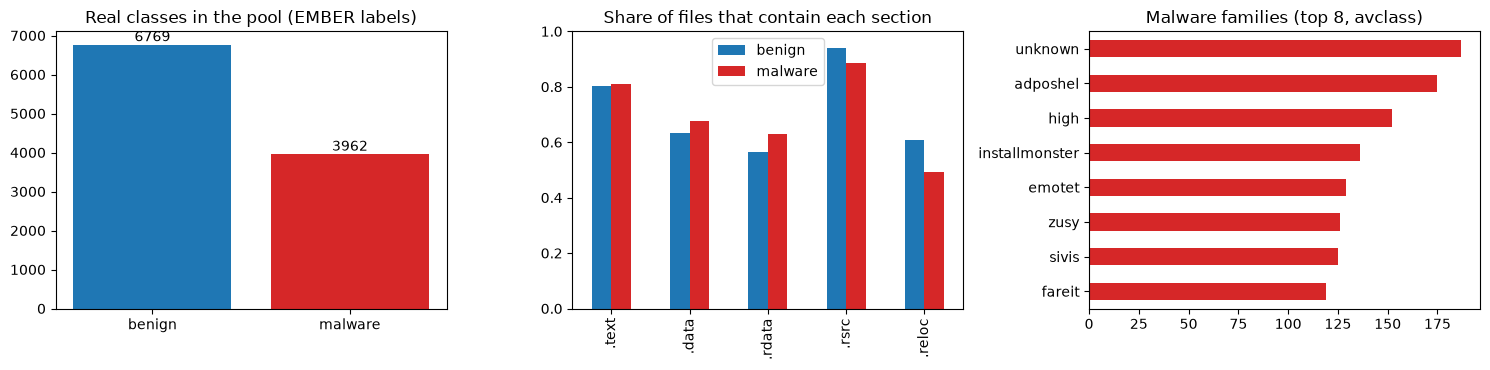

In [7]:
print("Pool table: one row per labelled PE file ->", (len(POOL_IDX), 5 * len(DESC_NAMES) + 256), "(5 sections x 13 descriptors + 256 byte-entropy bins)")
print("Descriptor names per section:", DESC_NAMES)
print("Byte-entropy histogram: 256 bins (16 x 16 'image' of the whole file)")
print("Original label values in EMBER: 0 = benign, 1 = malware, -1 = unlabelled (dropped). Counts in the pool:")
print(pd.Series(LABEL[POOL_IDX]).map({0: "benign (0)", 1: "malware (1)"}).value_counts().to_string())
print("\nSection presence (share of files containing the section):")
pres = pd.DataFrame({s: [HAS[s][POOL_IDX][LABEL[POOL_IDX] == c].mean() for c in (0, 1)] for s in SECTIONS}, index=["benign", "malware"])
print(pres.round(3).to_string())
print("\nTop malware families (avclass):")
fam_counts = pd.Series(FAMILY[POOL_IDX][LABEL[POOL_IDX] == 1]).value_counts()
print(fam_counts.head(10).to_string())
print("\nSubset sizes used by seed", SEEDS[0], "->", {k: len(v) for k, v in SP0.items()})
print("Files per QCNN (D1-train rows that contain the section):", {s: int(HAS[s][SP0['d1tr']].sum()) for s in SECTIONS})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cls = pd.Series(LABEL[POOL_IDX]).value_counts().sort_index()
ax[0].bar(["benign", "malware"], cls.values, color=["tab:blue", "tab:red"]); ax[0].set_title("Real classes in the pool (EMBER labels)")
for i, v in enumerate(cls.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
pres.T.plot.bar(ax=ax[1], color=["tab:blue", "tab:red"]); ax[1].set_title("Share of files that contain each section"); ax[1].set_ylim(0, 1)
fam_counts.head(8).iloc[::-1].plot.barh(ax=ax[2], color="tab:red"); ax[2].set_title("Malware families (top 8, avclass)")
plt.tight_layout(); plt.show()

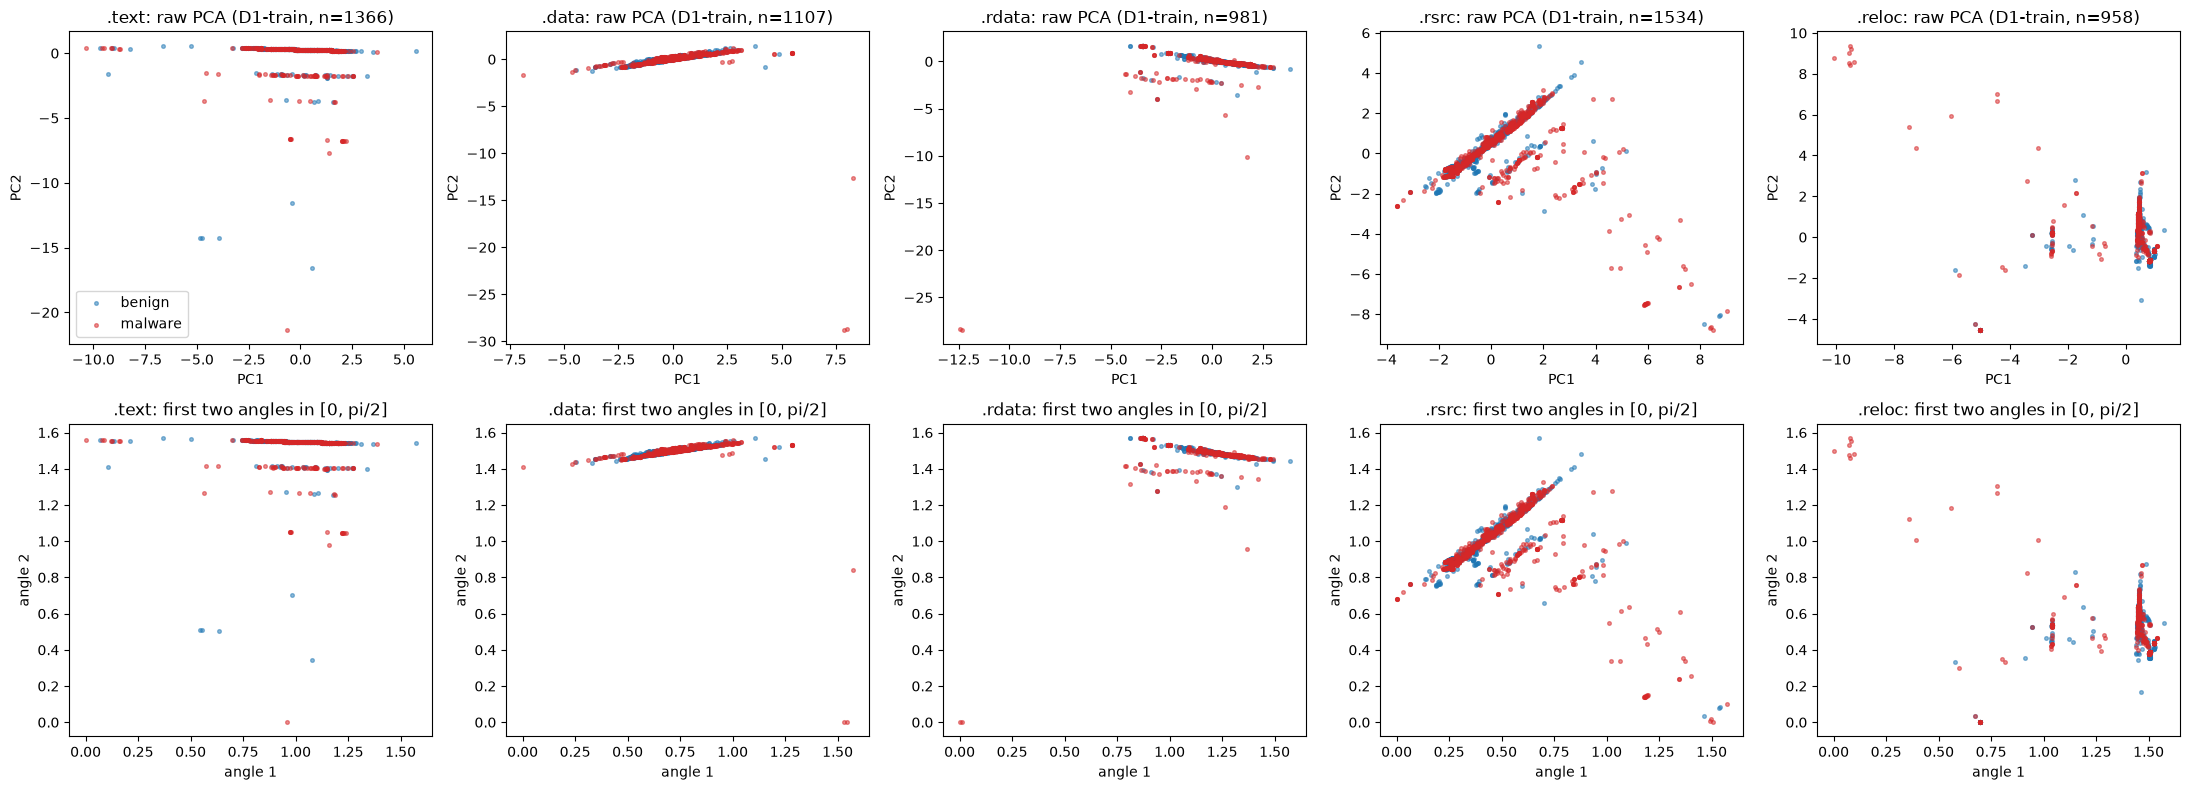

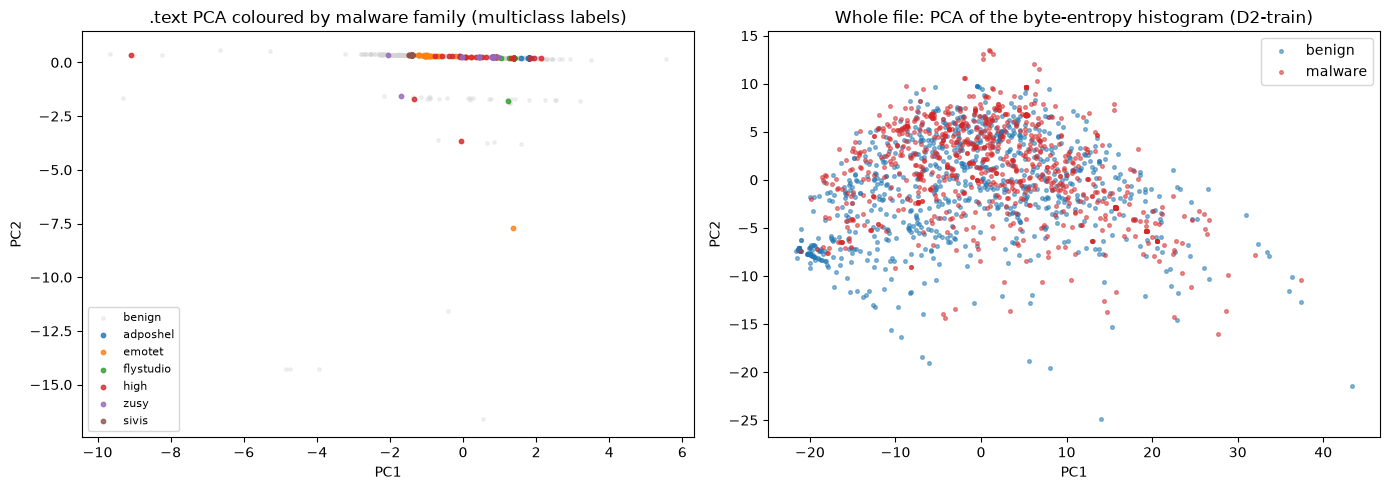

In [8]:
# 2-D scatter of REAL files, coloured by ground truth. Row 1: raw PCA coordinates (PC1, PC2); row 2: the first two QCNN angles.
fig, axs = plt.subplots(2, 5, figsize=(22, 8))
for j, s in enumerate(SECTIONS):
    rows = SP0["d1tr"][HAS[s][SP0["d1tr"]]]
    R = ENC0[s].raw(SEC_X[s][rows]); A = ENC0[s].angles(SEC_X[s][rows]); y = LABEL[rows]
    for c, col, nm in ((0, "tab:blue", "benign"), (1, "tab:red", "malware")):
        axs[0, j].scatter(R[y == c, 0], R[y == c, 1], s=7, alpha=0.5, c=col, label=nm)
        axs[1, j].scatter(A[y == c, 0], A[y == c, 1], s=7, alpha=0.5, c=col, label=nm)
    axs[0, j].set_title(f"{s}: raw PCA (D1-train, n={len(rows)})"); axs[0, j].set_xlabel("PC1"); axs[0, j].set_ylabel("PC2")
    axs[1, j].set_title(f"{s}: first two angles in [0, pi/2]"); axs[1, j].set_xlabel("angle 1"); axs[1, j].set_ylabel("angle 2")
axs[0, 0].legend(); plt.tight_layout(); plt.show()

# multiclass view: colour the .text plane by malware family (top 6) versus benign
s = ".text"; rows = SP0["d1tr"][HAS[s][SP0["d1tr"]]]
R = ENC0[s].raw(SEC_X[s][rows]); fam = FAMILY[rows]
top = [f for f in pd.Series(fam[LABEL[rows] == 1]).value_counts().index if f not in ("", "unknown")][:6]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(R[fam == "benign", 0], R[fam == "benign", 1], s=6, alpha=0.3, c="lightgrey", label="benign")
for f in top:
    ax[0].scatter(R[fam == f, 0], R[fam == f, 1], s=10, alpha=0.8, label=f)
ax[0].set_title(".text PCA coloured by malware family (multiclass labels)"); ax[0].legend(fontsize=8); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")

# whole-file view: PCA of the 256-value byte-entropy histogram (the input of the single-QCNN reference model, Table 3b)
enc_w0 = AngleEncoder(SEEDS[0]).fit(BYTE_ENT[SP0["d2tr"]])
Rw = enc_w0.raw(BYTE_ENT[SP0["d2tr"]]); yw = LABEL[SP0["d2tr"]]
for c, col, nm in ((0, "tab:blue", "benign"), (1, "tab:red", "malware")):
    ax[1].scatter(Rw[yw == c, 0], Rw[yw == c, 1], s=7, alpha=0.5, c=col, label=nm)
ax[1].set_title("Whole file: PCA of the byte-entropy histogram (D2-train)"); ax[1].legend(); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The QCNN of the paper (Fig. 3): 8 qubits, the data encoding of Eq. (1), then three layers of **convolution** (a parameterised two-qubit block on neighbouring pairs, first the pairs (0,1),(2,3),(4,5),(6,7), then the shifted pairs (1,2),(3,4),(5,6),(7,0)) and **pooling** (a parameterised two-qubit block from a *source* qubit onto a *sink* qubit; the sources are then dropped, which is the "tracing out" of the paper), until one qubit is left. That qubit (qubit 7) is measured in the Z basis: `<Z>` in [-1, 1] is the output.

**Assumptions where the paper omits the circuit details** (Fig. 4 is not in the extracted text): the conv/pool blocks are the 3-parameter two-qubit blocks of the Qiskit QCNN tutorial (RZ, RY, CX, as in Cong et al. 2019); parameters are shared inside a layer (translation invariance), so there are 3 parameters per conv layer and 3 per pool layer, 18 in total; the encoding `cos(x)|0> + sin(x)|1>` is realised as `RY(2x)|0>`. The 8 input angles are not trainable.

qubits: 8 | depth: 50 | gates: {'rz': 53, 'cx': 53, 'ry': 48} | trainable parameters: 18 | input angles: 8
drawing below = the executed circuit + the final Z measurement of qubit 7 (its expectation <Z> is the model output)


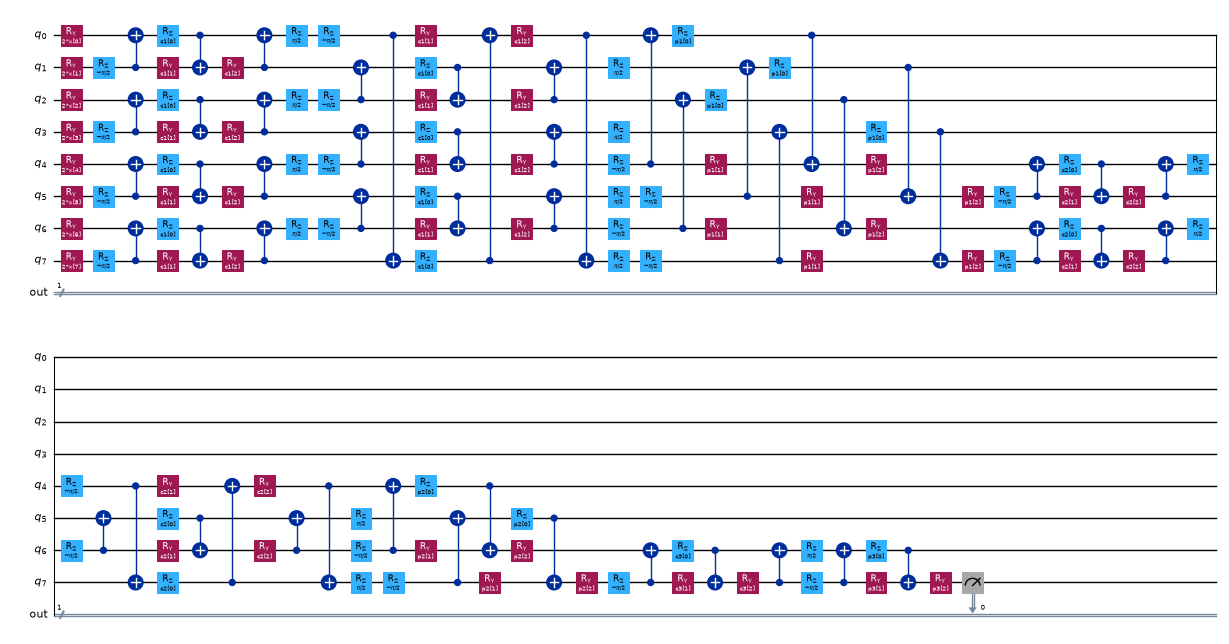

In [9]:
def conv_block(p):
    qc = QuantumCircuit(2, name="conv")
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1); qc.cx(0, 1); qc.ry(p[2], 1); qc.cx(1, 0); qc.rz(np.pi / 2, 0)
    return qc
def pool_block(p):
    qc = QuantumCircuit(2, name="pool")
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1); qc.cx(0, 1); qc.ry(p[2], 1)
    return qc
def conv_layer(n, prefix):
    qc = QuantumCircuit(n, name="C"); p = ParameterVector(prefix, 3); q = list(range(n))
    for a, b in zip(q[0::2], q[1::2]): qc.compose(conv_block(p), [a, b], inplace=True)
    if n > 2:
        for a, b in zip(q[1::2], q[2::2] + [q[0]]): qc.compose(conv_block(p), [a, b], inplace=True)
    return qc
def pool_layer(src, snk, prefix):
    qc = QuantumCircuit(len(src) + len(snk), name="P"); p = ParameterVector(prefix, 3)
    for a, b in zip(src, snk): qc.compose(pool_block(p), [a, b], inplace=True)
    return qc

LAYERS = [("C1", conv_layer(8, "c1"), list(range(8))), ("P1", pool_layer([0, 1, 2, 3], [4, 5, 6, 7], "p1"), list(range(8))),
          ("C2", conv_layer(4, "c2"), [4, 5, 6, 7]), ("P2", pool_layer([0, 1], [2, 3], "p2"), [4, 5, 6, 7]),
          ("C3", conv_layer(2, "c3"), [6, 7]), ("P3", pool_layer([0], [1], "p3"), [6, 7])]
VQC_ = QuantumCircuit(8)
for _, lay, qs in LAYERS:
    VQC_.compose(lay, qs, inplace=True)
WP = list(VQC_.parameters)                      # the 18 trainable parameters, in a fixed order

xs = ParameterVector("x", 8)                    # the 8 input angles
ENC = QuantumCircuit(8)
for i in range(8):
    ENC.ry(2 * xs[i], i)                        # RY(2x)|0> = cos(x)|0> + sin(x)|1>   (Eq. 1)
FULL = ENC.compose(VQC_)                        # THE circuit that is executed: encoding + 3 x (conv, pool)
OBS = SparsePauliOp("ZIIIIIII")                 # Z on qubit 7 (Qiskit is little-endian: leftmost character = qubit 7)

print("qubits:", FULL.num_qubits, "| depth:", FULL.depth(), "| gates:", dict(FULL.count_ops()),
      "| trainable parameters:", len(WP), "| input angles:", len(xs))
FULL_M = FULL.copy(); _cr = ClassicalRegister(1, "out"); FULL_M.add_register(_cr); FULL_M.measure(7, _cr[0])   # drawing only: the Z-basis readout of qubit 7
print("drawing below = the executed circuit + the final Z measurement of qubit 7 (its expectation <Z> is the model output)")
display(FULL_M.draw("mpl", fold=36, scale=0.5))

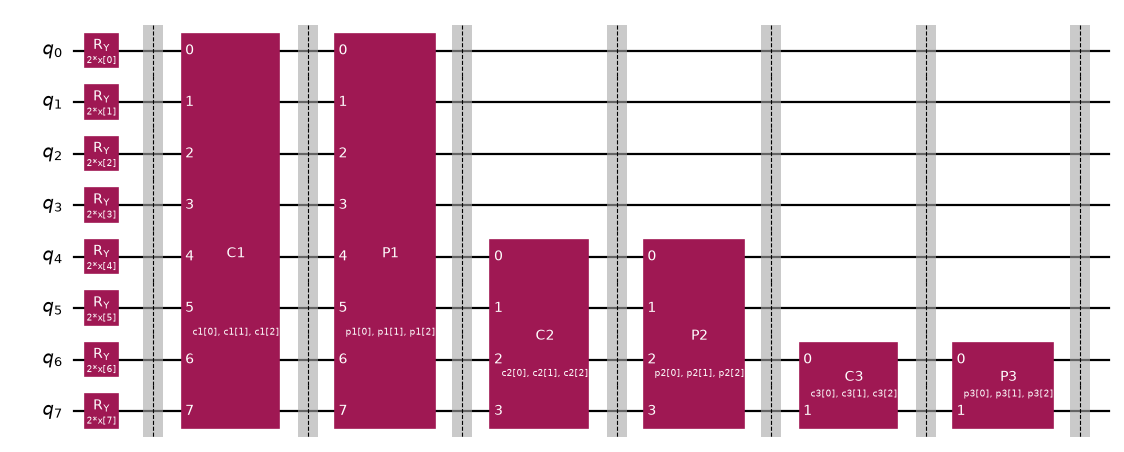

boxed circuit == flat circuit: OK


In [10]:
# Compact view of the SAME circuit: every conv / pool layer as one box. The assertion below shows that boxed and flat versions are the same unitary.
BOXED = QuantumCircuit(8)
for i in range(8):
    BOXED.ry(2 * xs[i], i)
BOXED.barrier()
for name, lay, qs in LAYERS:
    BOXED.append(lay.to_instruction(label=name), qs)
    BOXED.barrier()
display(BOXED.draw("mpl", scale=0.8, fold=-1))

rng_t = np.random.default_rng(1); th_t = rng_t.normal(size=len(WP)); x_t = rng_t.uniform(0, np.pi / 2, 8)
bind_flat = dict(zip(WP, th_t)); bind_flat.update(dict(zip(xs, x_t)))
by_name = {p.name: v for p, v in zip(WP, th_t)}; by_name.update({p.name: v for p, v in zip(xs, x_t)})
U_flat = Operator(FULL.assign_parameters(bind_flat)).data
U_boxed = Operator(BOXED.decompose().assign_parameters({p: by_name[p.name] for p in BOXED.decompose().parameters})).data
assert np.allclose(U_flat, U_boxed), "boxed and flat circuits differ"
print("boxed circuit == flat circuit: OK")

### A fast simulator that replays this circuit

Evaluating the circuit through Qiskit's estimator takes ~25 ms per sample, which is too slow for SPSA training on thousands of files. The small NumPy simulator below **reads the gate list of the circuit above** (`VQC_.data`: RZ, RY and CX gates) and applies it to a batch of product states. The next cell asserts that it gives the same `<Z>` as Qiskit's `Statevector` and as `EstimatorQNN` (qiskit-machine-learning) for the executed circuit.

In [11]:
ZD = np.array([1.0 if ((b >> 7) & 1) == 0 else -1.0 for b in range(256)])     # diagonal of Z on qubit 7

def product_states(X):
    # (cos x_i |0> + sin x_i |1>) on every qubit, qubit 0 = least significant bit
    psi = np.ones((len(X), 1))
    for q in range(7, -1, -1):
        two = np.stack([np.cos(X[:, q]), np.sin(X[:, q])], axis=1)
        psi = (psi[:, :, None] * two[:, None, :]).reshape(len(X), -1)
    return psi

_pidx = {p: i for i, p in enumerate(WP)}
GATES = []
for ins in VQC_.data:
    nm = ins.operation.name; qs = [VQC_.find_bit(q).index for q in ins.qubits]
    if nm == "cx":
        c, t = qs; idx = np.arange(256); perm = idx.copy(); m = ((idx >> c) & 1) == 1; perm[m] = idx[m] ^ (1 << t)
        GATES.append(("cx", perm, None, None))
    else:
        a = ins.operation.params[0]
        if hasattr(a, "parameters") and len(a.parameters) > 0:
            GATES.append((nm, qs[0], _pidx[list(a.parameters)[0]], None))
        else:
            GATES.append((nm, qs[0], None, float(a)))

def _rot(nm, ang):
    c, s = np.cos(ang / 2), np.sin(ang / 2)
    if nm == "ry":
        return np.array([[c, -s], [s, c]], dtype=complex)
    return np.array([[np.exp(-1j * ang / 2), 0], [0, np.exp(1j * ang / 2)]], dtype=complex)    # rz

def expz(psi, th):
    st = psi.astype(complex); n = len(st)
    for nm, a, pi_, const in GATES:
        if nm == "cx":
            st = st[:, a]
        else:
            G = _rot(nm, th[pi_] if pi_ is not None else const)
            st = np.einsum("ab,nibj->niaj", G, st.reshape(n, 2 ** (7 - a), 2, 2 ** a)).reshape(n, 256)
    return (np.abs(st) ** 2) @ ZD

# equivalence with Qiskit: Statevector of the executed circuit and EstimatorQNN
from qiskit_machine_learning.neural_networks import EstimatorQNN
Xchk = np.random.default_rng(2).uniform(0, np.pi / 2, (6, 8)); thchk = np.random.default_rng(3).normal(size=len(WP))
mine = expz(product_states(Xchk), thchk)
sv = np.array([Statevector(FULL.assign_parameters({**dict(zip(WP, thchk)), **dict(zip(xs, x))})).expectation_value(OBS).real for x in Xchk])
qnn = EstimatorQNN(circuit=FULL, observables=OBS, input_params=list(xs), weight_params=WP)
est = qnn.forward(Xchk, thchk)[:, 0]
assert np.allclose(mine, sv, atol=1e-10) and np.allclose(mine, est, atol=1e-8)
print("NumPy replay == Statevector == EstimatorQNN on 6 random inputs; max difference", float(max(np.abs(mine - sv).max(), np.abs(mine - est).max())))

NumPy replay == Statevector == EstimatorQNN on 6 random inputs; max difference 3.183217578417441e-16


## 3. Training one QCNN: SPSA, 5 epochs

The loss is the mean squared error between `<Z>` and the target (+1 malware, -1 benign). SPSA estimates the gradient from two loss evaluations per step at `theta +- c*delta` with a random `delta` in {-1, +1}^18 (a perturbation, not a derivative), then moves against it with a decaying step. One epoch is one pass over the training files in mini-batches of 16. The step-size scale `a` is picked from `A_GRID` on an inner validation part (20 %) of the training data only; the model is then retrained on the whole training part.

In [12]:
def spsa_train(Atr, ytr, seed, a, epochs=EPOCHS, batch=BATCH, c=C_SPSA, A=A_STAB):
    rng = np.random.default_rng(seed)
    th = rng.normal(0, INIT_STD, len(WP))
    ypm = 2.0 * ytr - 1.0; psi = product_states(Atr); k = 0; hist = []
    probe = np.arange(min(len(Atr), 300))
    for ep in range(epochs):
        perm = rng.permutation(len(Atr))
        for i in range(0, len(Atr), batch):
            b = perm[i:i + batch]
            ak = a / (k + 1 + A) ** 0.602; ck = c / (k + 1) ** 0.101
            d = rng.choice([-1.0, 1.0], len(th))
            lp = np.mean((expz(psi[b], th + ck * d) - ypm[b]) ** 2)
            lm = np.mean((expz(psi[b], th - ck * d) - ypm[b]) ** 2)
            th = th - ak * (lp - lm) / (2 * ck) * d; k += 1
        z = expz(psi[probe], th)
        hist.append((float(np.mean((z - ypm[probe]) ** 2)), float(np.mean((z > 0) == ytr[probe]))))
    return th, hist

class QCNNModel:
    # one trained QCNN: weights th; score(angles) = P(malware) = (1 + <Z>) / 2
    def __init__(self, th, hist, a):
        self.th, self.hist, self.a = th, hist, a
    def score(self, A):
        return (1.0 + expz(product_states(A), self.th)) / 2.0

def fit_qcnn(Atr, ytr, seed):
    n_in = int(0.8 * len(Atr)); perm = np.random.default_rng(seed).permutation(len(Atr)); a_i, v_i = perm[:n_in], perm[n_in:]
    best = (-1, None)
    for a in A_GRID:                                           # learning rate chosen on an inner validation split of the TRAINING data
        th, _ = spsa_train(Atr[a_i], ytr[a_i], seed, a)
        acc = np.mean((expz(product_states(Atr[v_i]), th) > 0) == ytr[v_i])
        if acc > best[0]:
            best = (acc, a)
    th, hist = spsa_train(Atr, ytr, seed, best[1])
    return QCNNModel(th, hist, best[1])

def metrics(y, pred):
    return dict(acc=accuracy_score(y, pred), f1=f1_score(y, pred, zero_division=0),
                prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred, zero_division=0))
print("training functions ready")

training functions ready


## 4. The full pipeline for one seed

For one seed the function below performs the paper's three stages, plus the classical comparisons on identical inputs:

1. **Stage 1 (D1).** One QCNN per section, trained on the D1-train files that contain the section (Table 1). Side by side: RF and SVC(rbf) on the very same 8 angles.
2. **Stage 2 (D2).** Every file of D2 and D3 gets five scores (-1 when the section is absent). XGBoost, LightGBM, RF and a majority vote are trained on the D2-train scores and evaluated on D2-val (Table 2) and on D3 (Table 3a).
3. **Reference (D2 -> D3).** One QCNN on the whole-file input (PCA of the byte-entropy histogram), trained on D2-train and tested on D3 (Table 3b).
4. **Classical twins.** (i) the same pipeline with a Random Forest per section instead of a QCNN, (ii) XGBoost on all raw section descriptors (+ presence flags), trained on D2-train.

In [13]:
def score_matrix(models, encs, idx):
    S = -np.ones((len(idx), len(SECTIONS)))
    for j, s in enumerate(SECTIONS):
        m = HAS[s][idx]
        if m.any():
            S[m, j] = models[s].score(encs[s].angles(SEC_X[s][idx[m]]))
    return S

def maj_vote(S):
    return ((S > 0.5).sum(1) >= 3).astype(int)

def make_scorers(seed):
    return {"XGBoost": xgb.XGBClassifier(n_estimators=TREES, max_depth=4, learning_rate=0.1, subsample=0.9, random_state=seed, n_jobs=2, verbosity=0),
            "LGBM": lgb.LGBMClassifier(n_estimators=TREES, max_depth=4, learning_rate=0.1, random_state=seed, n_jobs=2, verbose=-1),
            "RF": RandomForestClassifier(TREES, random_state=seed, n_jobs=2)}

def run_pipeline(seed, verbose=True):
    t0 = time.time(); algorithm_globals.random_seed = seed
    sp = make_splits(seed); encs = fit_section_encoders(sp, seed); R = {"seed": seed, "split": sp, "encs": encs}
    T1, qmod, rf_mod = [], {}, {}
    # ---- stage 1: one QCNN per section on D1 ----
    for s in SECTIONS:
        tr = sp["d1tr"][HAS[s][sp["d1tr"]]]; va = sp["d1va"][HAS[s][sp["d1va"]]]; te = sp["d3"][HAS[s][sp["d3"]]]
        Atr, Ava, Ate = (encs[s].angles(SEC_X[s][i]) for i in (tr, va, te))
        t1 = time.time(); m = fit_qcnn(Atr, LABEL[tr], seed); tq = time.time() - t1
        qmod[s] = m
        ptr, pva, pte = (m.score(A) > 0.5 for A in (Atr, Ava, Ate))
        rf = RandomForestClassifier(TREES, random_state=seed, n_jobs=2).fit(Atr, LABEL[tr]); rf_mod[s] = rf
        svc = SVC(kernel="rbf", random_state=seed).fit(Atr, LABEL[tr])
        row = dict(section=s, n_train=len(tr), a=m.a, qcnn_train_acc=metrics(LABEL[tr], ptr)["acc"],
                   **{"qcnn_val_" + k: v for k, v in metrics(LABEL[va], pva).items()},
                   qcnn_d3_acc=metrics(LABEL[te], pte)["acc"],
                   rf_val_acc=rf.score(Ava, LABEL[va]), rf_val_f1=f1_score(LABEL[va], rf.predict(Ava)),
                   svc_val_acc=svc.score(Ava, LABEL[va]), svc_val_f1=f1_score(LABEL[va], svc.predict(Ava)), qcnn_seconds=tq)
        T1.append(row); R.setdefault("hist", {})[s] = m.hist
        if verbose: print(f"  [seed {seed}] {s:7s} n={len(tr):4d} a={m.a} QCNN train {row['qcnn_train_acc']:.3f} val {row['qcnn_val_acc']:.3f} F1 {row['qcnn_val_f1']:.3f} | RF val {row['rf_val_acc']:.3f} | {tq:.0f}s", flush=True)
    R["T1"] = pd.DataFrame(T1); R["qmod"] = qmod
    # ---- stage 2: scores and scoring functions ----
    S = {k: score_matrix(qmod, encs, sp[k]) for k in ("d2tr", "d2va", "d3")}; R["S"] = S
    T2, T3a, preds = [], [], {}
    for name, clf in make_scorers(seed).items():
        clf.fit(S["d2tr"], LABEL[sp["d2tr"]])
        r = {"scorer": name}
        for k, tag in (("d2tr", "train"), ("d2va", "test")):
            m_ = metrics(LABEL[sp[k]], clf.predict(S[k])); r[tag + "_acc"], r[tag + "_f1"] = m_["acc"], m_["f1"]
        T2.append(r)
        m3 = metrics(LABEL[sp["d3"]], clf.predict(S["d3"])); preds[name] = clf.predict(S["d3"])
        T3a.append(dict(scorer=name, **m3)); R.setdefault("scorers", {})[name] = clf
    r = {"scorer": "Maj. vote"}
    for k, tag in (("d2tr", "train"), ("d2va", "test")):
        m_ = metrics(LABEL[sp[k]], maj_vote(S[k])); r[tag + "_acc"], r[tag + "_f1"] = m_["acc"], m_["f1"]
    T2.append(r); preds["Maj. vote"] = maj_vote(S["d3"]); T3a.append(dict(scorer="Maj. vote", **metrics(LABEL[sp["d3"]], preds["Maj. vote"])))
    R["T2"], R["T3a"], R["preds"] = pd.DataFrame(T2), pd.DataFrame(T3a), preds
    # ---- reference: ONE QCNN on the whole file ----
    encw = AngleEncoder(seed).fit(BYTE_ENT[sp["d2tr"]]); Aw_tr, Aw_te = encw.angles(BYTE_ENT[sp["d2tr"]]), encw.angles(BYTE_ENT[sp["d3"]])
    t1 = time.time(); mw = fit_qcnn(Aw_tr, LABEL[sp["d2tr"]], seed); tw = time.time() - t1
    ptr, pte = mw.score(Aw_tr) > 0.5, mw.score(Aw_te) > 0.5
    rfw = RandomForestClassifier(TREES, random_state=seed, n_jobs=2).fit(Aw_tr, LABEL[sp["d2tr"]]); svw = SVC(kernel="rbf", random_state=seed).fit(Aw_tr, LABEL[sp["d2tr"]])
    R["T3b"] = dict(train=metrics(LABEL[sp["d2tr"]], ptr), test=metrics(LABEL[sp["d3"]], pte), rf_test=metrics(LABEL[sp["d3"]], rfw.predict(Aw_te)),
                    svc_test=metrics(LABEL[sp["d3"]], svw.predict(Aw_te)), seconds=tw, hist=mw.hist, pred=pte.astype(int))
    # ---- classical twins ----
    Srf = {k: -np.ones((len(sp[k]), len(SECTIONS))) for k in ("d2tr", "d3")}
    for j, s in enumerate(SECTIONS):
        for k in Srf:
            m_ = HAS[s][sp[k]]
            if m_.any(): Srf[k][m_, j] = rf_mod[s].predict_proba(encs[s].angles(SEC_X[s][sp[k][m_]]))[:, 1]
    twin = make_scorers(seed)["XGBoost"].fit(Srf["d2tr"], LABEL[sp["d2tr"]])
    R["twin_rf_xgb"] = metrics(LABEL[sp["d3"]], twin.predict(Srf["d3"]))
    def raw_all(idx):
        return np.hstack([np.nan_to_num(SEC_X[s][idx], nan=0.0) for s in SECTIONS] + [np.stack([HAS[s][idx] for s in SECTIONS], 1).astype(float)])
    allx = make_scorers(seed)["XGBoost"].fit(raw_all(sp["d2tr"]), LABEL[sp["d2tr"]])
    R["xgb_raw_all"] = metrics(LABEL[sp["d3"]], allx.predict(raw_all(sp["d3"])))
    R["seconds"] = time.time() - t0
    if verbose: print(f"seed {seed} done in {R['seconds']:.0f} s", flush=True)
    return R
print("pipeline defined")

pipeline defined


## 5. Run

One run per seed in `SEEDS` (FAST_MODE: one seed).

In [14]:
RESULTS = [run_pipeline(sd) for sd in SEEDS]
print(f"total pipeline time: {sum(r['seconds'] for r in RESULTS)/60:.1f} min")

  [seed 0] .text   n=1366 a=1.0 QCNN train 0.501 val 0.506 F1 0.671 | RF val 0.737 | 37s


  [seed 0] .data   n=1107 a=0.3 QCNN train 0.515 val 0.517 F1 0.682 | RF val 0.764 | 31s


  [seed 0] .rdata  n= 981 a=0.3 QCNN train 0.505 val 0.488 F1 0.640 | RF val 0.810 | 32s


  [seed 0] .rsrc   n=1534 a=0.3 QCNN train 0.586 val 0.588 F1 0.340 | RF val 0.731 | 43s


  [seed 0] .reloc  n= 958 a=1.0 QCNN train 0.540 val 0.561 F1 0.146 | RF val 0.775 | 27s


...

  [seed 2] .rdata  n= 997 a=1.0 QCNN train 0.551 val 0.557 F1 0.703 | RF val 0.777 | 33s


  [seed 2] .rsrc   n=1542 a=0.3 QCNN train 0.587 val 0.573 F1 0.437 | RF val 0.766 | 50s


  [seed 2] .reloc  n= 896 a=0.3 QCNN train 0.568 val 0.567 F1 0.087 | RF val 0.767 | 30s


seed 2 done in 303 s


total pipeline time: 14.1 min


## 6. Training curves and what the five QCNNs learned

The curves show the mean squared error (left) and accuracy (right) on a fixed probe of up to 300 training files after every epoch. SPSA is noisy and only 18 parameters are available, so we should not expect miracles.

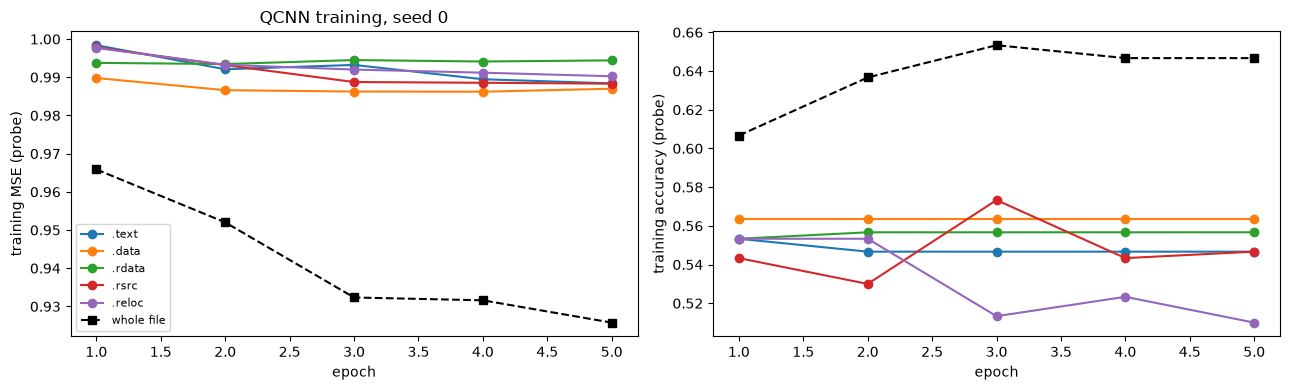

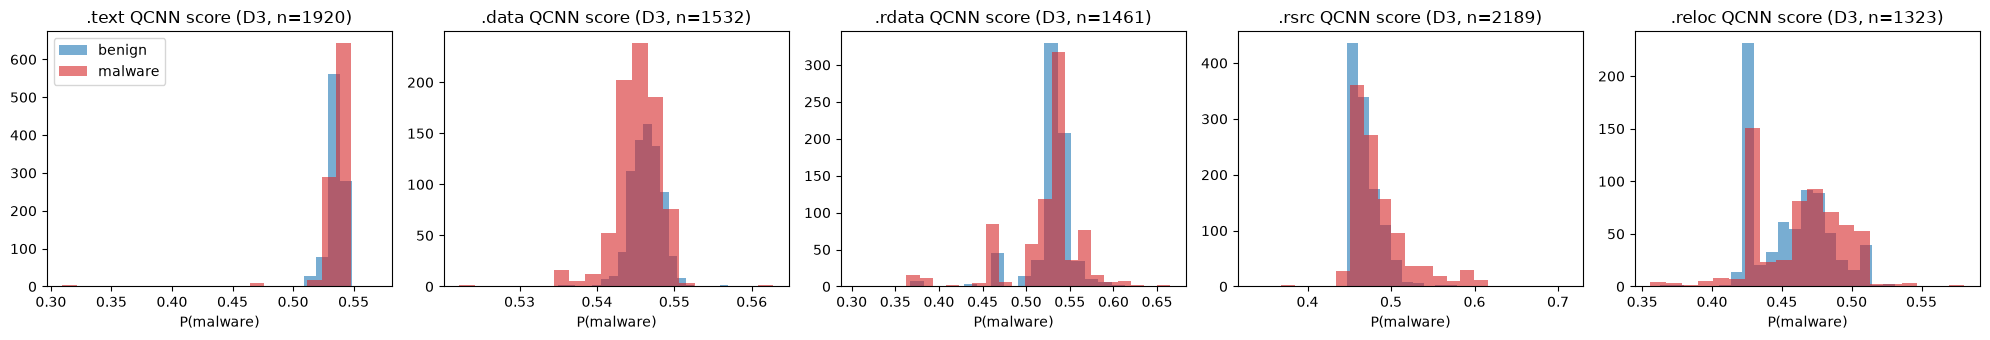

In [15]:
R0 = RESULTS[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s in SECTIONS:
    h = np.array(R0["hist"][s]); ax[0].plot(range(1, EPOCHS + 1), h[:, 0], marker="o", label=s); ax[1].plot(range(1, EPOCHS + 1), h[:, 1], marker="o", label=s)
hw = np.array(R0["T3b"]["hist"]); ax[0].plot(range(1, EPOCHS + 1), hw[:, 0], "k--", marker="s", label="whole file"); ax[1].plot(range(1, EPOCHS + 1), hw[:, 1], "k--", marker="s", label="whole file")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training MSE (probe)"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training accuracy (probe)"); ax[0].legend(fontsize=8)
ax[0].set_title(f"QCNN training, seed {R0['seed']}"); plt.tight_layout(); plt.show()

# score distributions by true class (the interpretability argument of the paper: which section looks suspicious?)
S3 = R0["S"]["d3"]; y3 = LABEL[R0["split"]["d3"]]
fig, ax = plt.subplots(1, 5, figsize=(20, 3.5))
for j, s in enumerate(SECTIONS):
    present = S3[:, j] >= 0
    ax[j].hist(S3[present & (y3 == 0), j], bins=20, alpha=0.6, color="tab:blue", label="benign"); ax[j].hist(S3[present & (y3 == 1), j], bins=20, alpha=0.6, color="tab:red", label="malware")
    ax[j].set_title(f"{s} QCNN score (D3, n={int(present.sum())})"); ax[j].set_xlabel("P(malware)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 7. Tables 1 to 3 (our numbers; mean +- std over seeds)

In [16]:
def ms(vals):
    vals = np.asarray(vals, float)
    return f"{vals.mean():.2f} +- {vals.std():.2f}" if len(vals) > 1 else f"{vals.mean():.2f}"

# ---- Table 1: per section ----
T1 = pd.concat([r["T1"].assign(seed=r["seed"]) for r in RESULTS])
t1 = T1.groupby("section", sort=False).agg(list)
tab1 = pd.DataFrame({"n_train (seed0)": [int(T1[(T1.seed == SEEDS[0]) & (T1.section == s)].n_train.iloc[0]) for s in SECTIONS]}, index=SECTIONS)
tab1["QCNN train acc"] = [ms(t1.loc[s, "qcnn_train_acc"]) for s in SECTIONS]
tab1["QCNN test acc"] = [ms(t1.loc[s, "qcnn_val_acc"]) for s in SECTIONS]
tab1["QCNN test F1"] = [ms(t1.loc[s, "qcnn_val_f1"]) for s in SECTIONS]
tab1["RF test acc (same 8 angles)"] = [ms(t1.loc[s, "rf_val_acc"]) for s in SECTIONS]
tab1["SVC test acc (same 8 angles)"] = [ms(t1.loc[s, "svc_val_acc"]) for s in SECTIONS]
print("Table 1 analogue: per-section QCNN (test = D1 validation split)"); display(tab1)

# ---- Table 2: scoring functions ----
T2 = pd.concat([r["T2"].assign(seed=r["seed"]) for r in RESULTS])
rows = []
for sc in ["XGBoost", "LGBM", "RF", "Maj. vote"]:
    d = T2[T2.scorer == sc]
    rows.append(dict(scorer=sc, **{c: ms(d[c]) for c in ("train_acc", "train_f1", "test_acc", "test_f1")}))
print("Table 2 analogue: scoring functions on the five QCNN scores (test = D2 validation split)"); display(pd.DataFrame(rows).set_index("scorer"))

# ---- Table 3a / 3b ----
T3a = pd.concat([r["T3a"].assign(seed=r["seed"]) for r in RESULTS])
print("Table 3a analogue: whole multi-QCNN pipeline on D3")
display(pd.DataFrame([dict(scorer=sc, **{c: ms(T3a[T3a.scorer == sc][c]) for c in ("acc", "f1", "prec", "rec")}) for sc in ["RF", "XGBoost", "LGBM", "Maj. vote"]]).set_index("scorer"))
b = [r["T3b"] for r in RESULTS]
print("Table 3b analogue: ONE QCNN on the whole-file input (train on D2-train, test on D3)")
display(pd.DataFrame({"Accuracy": [ms([x["train"]["acc"] for x in b]), ms([x["test"]["acc"] for x in b])],
                      "F1-score": [ms([x["train"]["f1"] for x in b]), ms([x["test"]["f1"] for x in b])]}, index=["Train", "Test (D3)"]))

# ---- classical comparison on identical inputs (D3) ----
cmp_rows = [("Multi-QCNN + XGBoost (paper's model)", T3a[T3a.scorer == "XGBoost"].acc, T3a[T3a.scorer == "XGBoost"].f1),
            ("Classical twin: RF per section + XGBoost", [r["twin_rf_xgb"]["acc"] for r in RESULTS], [r["twin_rf_xgb"]["f1"] for r in RESULTS]),
            ("XGBoost on all raw section descriptors", [r["xgb_raw_all"]["acc"] for r in RESULTS], [r["xgb_raw_all"]["f1"] for r in RESULTS]),
            ("Single QCNN, whole file", [x["test"]["acc"] for x in b], [x["test"]["f1"] for x in b]),
            ("RF, whole file (same 8 angles)", [x["rf_test"]["acc"] for x in b], [x["rf_test"]["f1"] for x in b]),
            ("SVC rbf, whole file (same 8 angles)", [x["svc_test"]["acc"] for x in b], [x["svc_test"]["f1"] for x in b])]
print("Quantum versus classical on D3"); display(pd.DataFrame([dict(model=n, accuracy=ms(a), f1=ms(f)) for n, a, f in cmp_rows]).set_index("model"))
print("Wall-clock per seed: stage-1 QCNN training %.0f s (5 sections), single whole-file QCNN %.0f s, whole seed %.0f s" % (
    RESULTS[0]["T1"].qcnn_seconds.sum(), RESULTS[0]["T3b"]["seconds"], RESULTS[0]["seconds"]))

Table 1 analogue: per-section QCNN (test = D1 validation split)


,n_train (seed0),QCNN train acc,QCNN test acc,QCNN test F1,RF test acc (same 8 angles),SVC test acc (same 8 angles)
.text,1366,0.54 +- 0.04,0.52 +- 0.03,0.54 +- 0.16,0.75 +- 0.01,0.62 +- 0.03
.data,1107,0.51 +- 0.03,0.52 +- 0.01,0.54 +- 0.10,0.77 +- 0.02,0.57 +- 0.02
.rdata,981,0.52 +- 0.03,0.52 +- 0.03,0.67 +- 0.03,0.79 +- 0.01,0.56 +- 0.02
.rsrc,1534,0.58 +- 0.00,0.57 +- 0.02,0.42 +- 0.06,0.74 +- 0.02,0.60 +- 0.00
.reloc,958,0.56 +- 0.02,0.57 +- 0.01,0.15 +- 0.05,0.76 +- 0.01,0.59 +- 0.01


Table 2 analogue: scoring functions on the five QCNN scores (test = D2 validation split)


,train_acc,train_f1,test_acc,test_f1
scorer,,,,
XGBoost,0.92 +- 0.01,0.92 +- 0.01,0.74 +- 0.03,0.75 +- 0.03
LGBM,0.90 +- 0.01,0.90 +- 0.01,0.74 +- 0.03,0.74 +- 0.03
RF,1.00 +- 0.00,1.00 +- 0.00,0.77 +- 0.03,0.77 +- 0.03
Maj. vote,0.54 +- 0.00,0.37 +- 0.13,0.53 +- 0.01,0.37 +- 0.14


Table 3a analogue: whole multi-QCNN pipeline on D3


...

Table 3b analogue: ONE QCNN on the whole-file input (train on D2-train, test on D3)


,Accuracy,F1-score
Train,0.66 +- 0.02,0.70 +- 0.02
Test (D3),0.65 +- 0.02,0.69 +- 0.03


Quantum versus classical on D3


,accuracy,f1
model,,
Multi-QCNN + XGBoost (paper's model),0.78 +- 0.02,0.78 +- 0.02
Classical twin: RF per section + XGBoost,0.82 +- 0.00,0.82 +- 0.00
XGBoost on all raw section descriptors,0.83 +- 0.00,0.83 +- 0.00
"Single QCNN, whole file",0.65 +- 0.02,0.69 +- 0.03
"RF, whole file (same 8 angles)",0.77 +- 0.00,0.77 +- 0.00
"SVC rbf, whole file (same 8 angles)",0.74 +- 0.01,0.75 +- 0.01


Wall-clock per seed: stage-1 QCNN training 170 s (5 sections), single whole-file QCNN 34 s, whole seed 249 s


### Confusion matrices on D3 (malware = positive class)

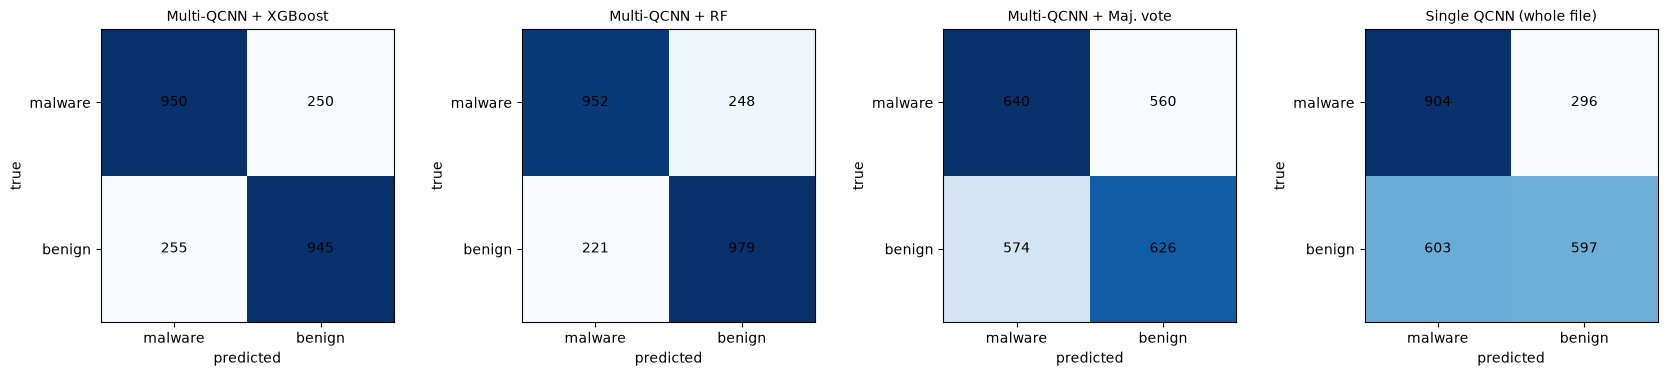

Random-forest importance of each section score: {'.text': np.float64(0.22), '.data': np.float64(0.171), '.rdata': np.float64(0.152), '.rsrc': np.float64(0.299), '.reloc': np.float64(0.159)}


In [17]:
y3 = LABEL[RESULTS[0]["split"]["d3"]]
panels = [("Multi-QCNN + XGBoost", RESULTS[0]["preds"]["XGBoost"]), ("Multi-QCNN + RF", RESULTS[0]["preds"]["RF"]),
          ("Multi-QCNN + Maj. vote", RESULTS[0]["preds"]["Maj. vote"]), ("Single QCNN (whole file)", RESULTS[0]["T3b"]["pred"])]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a_, (nm, p) in zip(ax, panels):
    cm = confusion_matrix(y3, p, labels=[1, 0]); a_.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a_.text(j, i, cm[i, j], ha="center", va="center", color="black")
    a_.set_xticks([0, 1], ["malware", "benign"]); a_.set_yticks([0, 1], ["malware", "benign"]); a_.set_xlabel("predicted"); a_.set_ylabel("true"); a_.set_title(nm, fontsize=10)
plt.tight_layout(); plt.show()

# which section matters most? (the paper suggests reading the random-forest importances)
imp = np.mean([r["scorers"]["RF"].feature_importances_ for r in RESULTS], axis=0)
print("Random-forest importance of each section score:", dict(zip(SECTIONS, imp.round(3))))

## 8. Paper versus this notebook

Verdict rule: `reproduced` when our mean lies within 0.02 of the paper (accuracy or F1), `exceeded` when it is more than 0.02 above, `not reached` when it is more than 0.02 below. Qualitative claims are judged from the numbers above. Remember that the inputs differ (section descriptors from EMBER instead of section byte images, and far fewer files), so a gap says more about the substitution than about the paper.

In [18]:
def verdict(paper, mine, tol=0.02):
    if mine > paper + tol: return "exceeded"
    if mine < paper - tol: return "not reached"
    return "reproduced"
mean = lambda x: float(np.mean(x))
PAPER_T1 = {".text": (0.67, 0.69, 0.68), ".data": (0.56, 0.55, 0.70), ".rdata": (0.66, 0.66, 0.78), ".rsrc": (0.65, 0.63, 0.72), ".reloc": (0.69, 0.70, 0.67)}
PAPER_T2 = {"XGBoost": (0.89, 0.90, 0.84, 0.85), "LGBM": (0.84, 0.86, 0.82, 0.85), "RF": (0.99, 0.99, 0.85, 0.86)}
rows = []
for s in SECTIONS:
    d = T1[T1.section == s]
    for nm, pv, mv in (("train acc", PAPER_T1[s][0], mean(d.qcnn_train_acc)), ("test acc", PAPER_T1[s][1], mean(d.qcnn_val_acc)), ("test F1", PAPER_T1[s][2], mean(d.qcnn_val_f1))):
        rows.append(("Table 1", f"{s} {nm}", pv, mv))
for sc, (a, f, ta, tf) in PAPER_T2.items():
    d = T2[T2.scorer == sc]
    for nm, pv, mv in (("train acc", a, mean(d.train_acc)), ("train F1", f, mean(d.train_f1)), ("test acc", ta, mean(d.test_acc)), ("test F1", tf, mean(d.test_f1))):
        rows.append(("Table 2", f"{sc} {nm}", pv, mv))
d = T2[T2.scorer == "Maj. vote"]
rows += [("Table 2", "Maj. vote test acc", 0.40, mean(d.test_acc)), ("Table 2", "Maj. vote test F1", 0.27, mean(d.test_f1))]
for sc, (pa, pf) in {"RF": (0.82, 0.80), "XGBoost": (0.83, 0.83)}.items():
    d = T3a[T3a.scorer == sc]; rows += [("Table 3a", f"multi-QCNN + {sc} acc", pa, mean(d.acc)), ("Table 3a", f"multi-QCNN + {sc} F1", pf, mean(d.f1))]
rows += [("Table 3b", "single QCNN train acc", 0.68, mean([x["train"]["acc"] for x in b])), ("Table 3b", "single QCNN train F1", 0.70, mean([x["train"]["f1"] for x in b])),
         ("Table 3b", "single QCNN test acc", 0.60, mean([x["test"]["acc"] for x in b])), ("Table 3b", "single QCNN test F1", 0.66, mean([x["test"]["f1"] for x in b]))]
cmp = pd.DataFrame(rows, columns=["table", "quantity", "paper", "this notebook"])
cmp["gap"] = (cmp["this notebook"] - cmp["paper"]).round(3); cmp["verdict"] = [verdict(p, m) for p, m in zip(cmp.paper, cmp["this notebook"])]
cmp["this notebook"] = cmp["this notebook"].round(3)
display(cmp)

xgb_acc = mean(T3a[T3a.scorer == "XGBoost"].acc); sq_acc = mean([x["test"]["acc"] for x in b]); rf_acc = mean(T3a[T3a.scorer == "RF"].acc)
sec_test = [mean(T1[T1.section == s].qcnn_val_acc) for s in SECTIONS]
mv_acc = mean(T2[T2.scorer == "Maj. vote"].test_acc); xg_t2 = mean(T2[T2.scorer == "XGBoost"].test_acc)
claims = [
    ("(a) single sections are weak (0.55-0.70 test accuracy)", "reproduced" if all(0.50 <= v <= 0.75 for v in sec_test) else "not reached", f"section test accuracies {np.round(sec_test, 2).tolist()}"),
    ("(b) combining five section QCNNs lifts accuracy by about 20 points over one whole-file QCNN", "reproduced" if xgb_acc - sq_acc >= 0.15 else "not reached", f"XGBoost {xgb_acc:.3f} vs single QCNN {sq_acc:.3f} (gap {xgb_acc - sq_acc:+.3f}; paper +0.23)"),
    ("(c) XGBoost slightly better than RF on D3", "reproduced" if xgb_acc >= rf_acc - 0.005 else "not reached", f"XGBoost {xgb_acc:.3f} vs RF {rf_acc:.3f} (paper 0.83 vs 0.82)"),
    ("(d) majority vote is useless", "reproduced" if mv_acc < xg_t2 - 0.1 else "not reached", f"majority vote {mv_acc:.3f} vs XGBoost {xg_t2:.3f} on D2-val (paper 0.40 vs 0.84)"),
    ("(e) per-section scores point to the suspicious section", "cannot be checked", "no ground truth about which section is malicious; see the RF importances above"),
    ("Absolute numbers on the paper's data (BODMAS + PEMachineLearning, section byte images, 20k+20k per set)", "cannot be checked", "raw PE bytes not available; section descriptors from EMBER 2018 used instead"),
]
display(pd.DataFrame(claims, columns=["claim", "verdict", "evidence"]))
print("\nverdict counts for the numeric rows:", cmp.verdict.value_counts().to_dict())

,table,quantity,paper,this notebook,gap,verdict
0,Table 1,.text train acc,0.67,0.540,-0.130,not reached
1,Table 1,.text test acc,0.69,0.523,-0.167,not reached
2,Table 1,.text test F1,0.68,0.539,-0.141,not reached
3,Table 1,.data train acc,0.56,0.514,-0.046,not reached
4,Table 1,.data test acc,0.55,0.520,-0.030,not reached
5,Table 1,.data test F1,0.70,0.540,-0.160,not reached
6,Table 1,.rdata train acc,0.66,0.516,-0.144,not reached
7,Table 1,.rdata test acc,0.66,0.521,-0.139,not reached
8,Table 1,.rdata test F1,0.78,0.672,-0.108,not reached
9,Table 1,.rsrc train acc,0.65,0.583,-0.067,not reached


,claim,verdict,evidence
0,(a) single sections are weak (0.55-0.70 test a...,reproduced,"section test accuracies [0.52, 0.52, 0.52, 0.5..."
1,(b) combining five section QCNNs lifts accurac...,not reached,XGBoost 0.781 vs single QCNN 0.649 (gap +0.132...
2,(c) XGBoost slightly better than RF on D3,not reached,XGBoost 0.781 vs RF 0.799 (paper 0.83 vs 0.82)
3,(d) majority vote is useless,reproduced,majority vote 0.534 vs XGBoost 0.744 on D2-val...
4,(e) per-section scores point to the suspicious...,cannot be checked,no ground truth about which section is malicio...
5,Absolute numbers on the paper's data (BODMAS +...,cannot be checked,raw PE bytes not available; section descriptor...



verdict counts for the numeric rows: {'not reached': 24, 'exceeded': 8, 'reproduced': 5}


## 9. Reading the paper critically

Numbers below are from the full run in this notebook (3 seeds, 1 200 + 1 200 files per sub-dataset, EMBER section descriptors); they will move slightly if you change the seeds.

* **The idea survives, the quantum part does not carry it.** Combining five section-specific models with a learned scoring function clearly beats one model on the whole file: multi-QCNN + XGBoost reaches about 0.78 accuracy / 0.78 F1 on D3 against 0.65 / 0.69 for one QCNN on the whole-file input, a gap of about 13 points (the paper reports +23 points, 0.83 versus 0.60). But the **classical twin of the pipeline** (a Random Forest per section instead of a QCNN, then the same XGBoost) reaches 0.82, and XGBoost on all raw section descriptors reaches 0.83. On identical 8-angle inputs a Random Forest scores 0.74-0.79 per section where the 18-parameter QCNN scores 0.52-0.57. The paper never shows such a baseline, so its section-wise gain cannot be attributed to quantum computing; here it is the decomposition into sections and the scoring function that help.
* **The QCNN is weak mostly because it is tiny.** With weights shared inside every layer, 18 parameters and one measured qubit, the model is close to a linear-ish threshold on a few combinations of the angles; its per-section accuracy (0.52-0.57) sits below the paper's 0.55-0.70, and the F1 values are erratic because the model often predicts almost only one class (see the `.reloc` F1 of about 0.15). Unshared weights, more epochs, a better optimiser than SPSA with a handful of epochs, or a trainable bias would all be natural first steps (exercises 1-2). The paper's much larger training sets (28 000 files per QCNN) may also matter.
* **A substitute input, not the paper's input.** The paper uses 8 x 8 grayscale images of section *bytes*; EMBER offers only section *metadata* (sizes, entropy, flags). Our per-section classical accuracy of about 0.75 is therefore a statement about metadata, not about section content, and the comparison with Table 1 is indicative only.
* **Table 1 reading.** The paper's `Test` column and its F1 values (for instance `.data` accuracy 0.55 but F1 0.70) show that some QCNNs predict mostly the positive class; the split used for the test column is not stated (we use the D1 validation split).
* **Majority vote.** The paper's 0.40 accuracy is below chance and mostly reflects how the score -1 of missing sections enters the vote; with our definition (absent sections vote benign, at least 3 of 5 votes needed) the vote is a poor but not inverted classifier (about 0.53). Choosing -1 instead of 0.5 for missing sections is sensible for tree models, since the absence of `.reloc` or `.text` is itself informative (the presence table above shows it differs between benign and malicious files).
* **Training versus test of the scoring function.** The Random Forest reaches 1.00 on the training part of D2 and about 0.77 on its validation part, the same over-fitting pattern as in the paper (0.99 versus 0.85). Boosting overfits less.
* **Dataset effects.** In EMBER the benign files include many old (2009-2010) executables while malware is mostly from 2018; a model on section sizes and flags can partly learn the era of a file instead of maliciousness. The paper's BODMAS data have a single collection period for malware.
* **Interpretability claim (e).** The Random Forest importances (about 0.30 for `.rsrc`, 0.22 for `.text`, 0.15-0.17 for the others) show which section score the scoring function relies on, but without ground truth about where the malicious content sits this cannot be called detection of the suspicious section.
* **Reproducibility.** The paper does not give the conv/pool gate content (Fig. 4), the loss, learning rate, batch size, SPSB hyper-parameters, XGBoost settings or the exact definition of the "test" column; all of these are `# CHOICE:` items here.

## 10. Exercises

1. **More epochs, more steps.** Set `EPOCHS = 20` and `BATCH = 8`. Does a section QCNN approach the Random Forest on the same 8 angles, or does the 18-parameter circuit saturate?
2. **Unshared weights.** Give every conv/pool block its own 3 parameters (instead of sharing them inside a layer; about 3 x 8 = 24 for the first conv layer). Measure whether accuracy rises and how much slower SPSA becomes.
3. **The missing-section score.** Replace -1 by 0.5 (the authors' first idea) or by 0, retrain only the scoring function and compare accuracy and F1. Why does the choice matter for tree models and for a majority vote?
4. **A sixth section.** Add `.idata` or `.rsrc`-sized features as a sixth QCNN without retraining the other five (the paper's selling point) and check the change in D3 accuracy.
5. **Real section bytes.** If you have legally obtained PE files, replace the section descriptors by the paper's 8 x 8 grayscale images (read the section bytes with `lief` or `pefile`, resample to 8 x 8) and re-run stage 1 only. Do the QCNN accuracies move toward Table 1?